WHAT-IF BUSINESS SIMULATOR

BASELINE BUSINESS PERFORMANCE
units_sold: 1,000.00
selling_price: 500.00
variable_cost_per_unit: 300.00
fixed_cost: ₹100,000.00
revenue: ₹500,000.00
total_variable_cost: ₹300,000.00
total_cost: ₹400,000.00
profit: ₹100,000.00
profit_margin_pct: 20.00%
contribution_per_unit: 200.00
break_even_units: 500

SCENARIO COMPARISON
              scenario  revenue  total_cost   profit  profit_margin_pct  break_even_units  profit_change
              Baseline 500000.0    400000.0 100000.0              20.00               500            0.0
          Sales Growth 575000.0    450000.0 125000.0              21.74               525        25000.0
         Cost Pressure 500000.0    435000.0  65000.0              13.00               618       -35000.0
       Price Reduction 522500.0    430000.0  92500.0              17.70               572        -7500.0
Efficiency Improvement 525000.0    384800.0 140200.0              26.70               425        40200.0
        Demand De

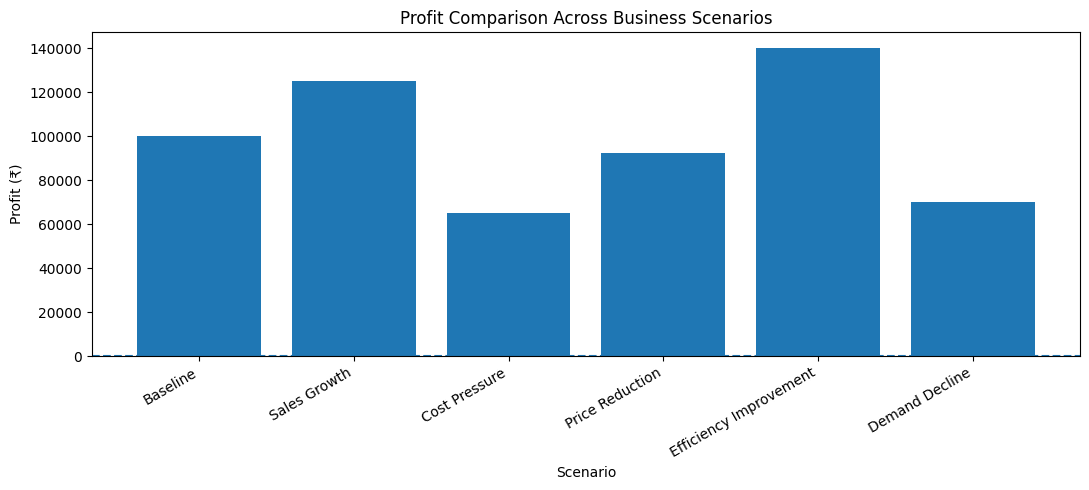

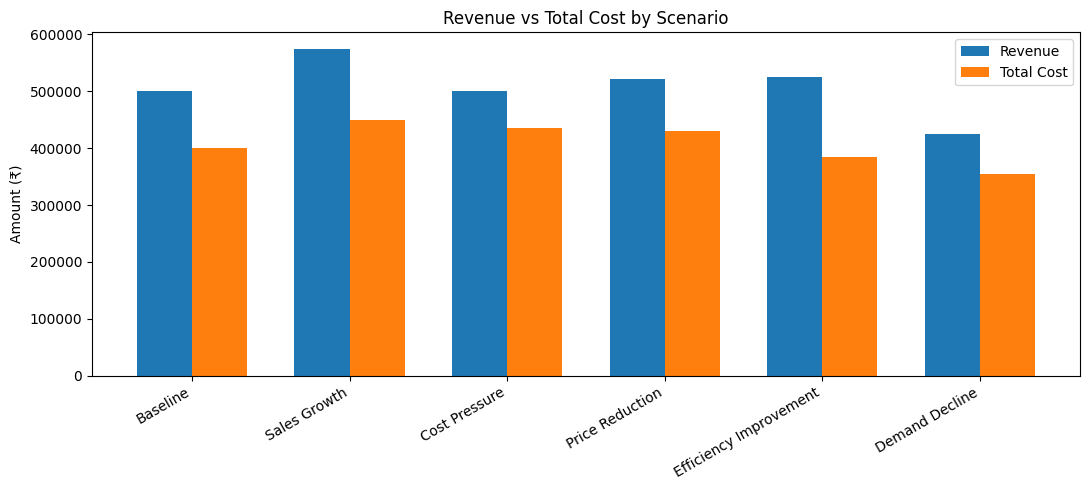


SCENARIO INSIGHTS
Highest-profit scenario: Efficiency Improvement (₹140,200.00)
Lowest-profit scenario: Cost Pressure (₹65,000.00)

BUSINESS RECOMMENDATIONS
1. Evaluate the assumptions behind the Efficiency Improvement scenario.
2. Investigate the drivers of the Cost Pressure scenario.
4. Use break-even estimates when planning sales targets.
5. Test multiple assumptions before making major pricing, cost, or capacity decisions.

CUSTOM SCENARIO
Volume change (%): 10
Price change (%): 0
Variable cost change (%): 5
Fixed cost change (%): 0
Revenue: ₹550,000.00
Total cost: ₹446,500.00
Profit: ₹103,500.00
Profit margin: 18.82%
Break-even units: 541

Results exported to:
what_if_business_simulator_results.csv

DISCLAIMER
This simulator uses illustrative assumptions, not real company data.
Actual business results may differ from these scenario estimates.


In [1]:

# PROJECT 14: WHAT-IF BUSINESS SIMULATOR

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

# --------------------------------------------------
# 1. DEFINE BASELINE BUSINESS ASSUMPTIONS
# --------------------------------------------------

base_units_sold = 1000
base_selling_price = 500
base_variable_cost = 300
base_fixed_cost = 100000

def calculate_business_metrics(
    units_sold,
    selling_price,
    variable_cost_per_unit,
    fixed_cost
):
    revenue = units_sold * selling_price
    total_variable_cost = units_sold * variable_cost_per_unit
    total_cost = total_variable_cost + fixed_cost
    profit = revenue - total_cost

    profit_margin = (
        profit / revenue * 100 if revenue != 0 else 0
    )

    contribution_per_unit = selling_price - variable_cost_per_unit

    if contribution_per_unit > 0:
        break_even_units = math.ceil(
            fixed_cost / contribution_per_unit
        )
    else:
        break_even_units = None

    return {
        "units_sold": units_sold,
        "selling_price": selling_price,
        "variable_cost_per_unit": variable_cost_per_unit,
        "fixed_cost": fixed_cost,
        "revenue": revenue,
        "total_variable_cost": total_variable_cost,
        "total_cost": total_cost,
        "profit": profit,
        "profit_margin_pct": profit_margin,
        "contribution_per_unit": contribution_per_unit,
        "break_even_units": break_even_units
    }

# --------------------------------------------------
# 2. CALCULATE THE BASELINE SCENARIO
# --------------------------------------------------

baseline = calculate_business_metrics(
    base_units_sold,
    base_selling_price,
    base_variable_cost,
    base_fixed_cost
)

print("=" * 55)
print("WHAT-IF BUSINESS SIMULATOR")
print("=" * 55)

print("\nBASELINE BUSINESS PERFORMANCE")

for metric, value in baseline.items():
    if metric in [
        "revenue",
        "total_variable_cost",
        "total_cost",
        "profit",
        "fixed_cost"
    ]:
        print(f"{metric}: ₹{value:,.2f}")
    elif metric == "profit_margin_pct":
        print(f"{metric}: {value:.2f}%")
    elif metric == "break_even_units":
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:,.2f}")

# --------------------------------------------------
# 3. DEFINE WHAT-IF BUSINESS SCENARIOS
# --------------------------------------------------

scenario_inputs = [
    {
        "scenario": "Baseline",
        "volume_change_pct": 0,
        "price_change_pct": 0,
        "variable_cost_change_pct": 0,
        "fixed_cost_change_pct": 0
    },
    {
        "scenario": "Sales Growth",
        "volume_change_pct": 15,
        "price_change_pct": 0,
        "variable_cost_change_pct": 0,
        "fixed_cost_change_pct": 5
    },
    {
        "scenario": "Cost Pressure",
        "volume_change_pct": 0,
        "price_change_pct": 0,
        "variable_cost_change_pct": 10,
        "fixed_cost_change_pct": 5
    },
    {
        "scenario": "Price Reduction",
        "volume_change_pct": 10,
        "price_change_pct": -5,
        "variable_cost_change_pct": 0,
        "fixed_cost_change_pct": 0
    },
    {
        "scenario": "Efficiency Improvement",
        "volume_change_pct": 5,
        "price_change_pct": 0,
        "variable_cost_change_pct": -8,
        "fixed_cost_change_pct": -5
    },
    {
        "scenario": "Demand Decline",
        "volume_change_pct": -15,
        "price_change_pct": 0,
        "variable_cost_change_pct": 0,
        "fixed_cost_change_pct": 0
    }
]

# --------------------------------------------------
# 4. CALCULATE RESULTS FOR EACH SCENARIO
# --------------------------------------------------

results = []

for scenario in scenario_inputs:
    units = round(
        base_units_sold
        * (1 + scenario["volume_change_pct"] / 100)
    )

    price = (
        base_selling_price
        * (1 + scenario["price_change_pct"] / 100)
    )

    variable_cost = (
        base_variable_cost
        * (1 + scenario["variable_cost_change_pct"] / 100)
    )

    fixed_cost = (
        base_fixed_cost
        * (1 + scenario["fixed_cost_change_pct"] / 100)
    )

    metrics = calculate_business_metrics(
        units,
        price,
        variable_cost,
        fixed_cost
    )

    metrics["scenario"] = scenario["scenario"]
    metrics["volume_change_pct"] = scenario["volume_change_pct"]
    metrics["price_change_pct"] = scenario["price_change_pct"]
    metrics["variable_cost_change_pct"] = (
        scenario["variable_cost_change_pct"]
    )
    metrics["fixed_cost_change_pct"] = (
        scenario["fixed_cost_change_pct"]
    )

    results.append(metrics)

results_df = pd.DataFrame(results)

# --------------------------------------------------
# 5. COMPARE PROFIT WITH THE BASELINE
# --------------------------------------------------

baseline_profit = baseline["profit"]
baseline_revenue = baseline["revenue"]

results_df["profit_change"] = (
    results_df["profit"] - baseline_profit
)

results_df["profit_change_pct"] = np.where(
    baseline_profit != 0,
    results_df["profit_change"] / abs(baseline_profit) * 100,
    np.nan
)

results_df["revenue_change"] = (
    results_df["revenue"] - baseline_revenue
)

print("\nSCENARIO COMPARISON")

display_columns = [
    "scenario",
    "revenue",
    "total_cost",
    "profit",
    "profit_margin_pct",
    "break_even_units",
    "profit_change"
]

print(
    results_df[display_columns]
    .round(2)
    .to_string(index=False)
)

# --------------------------------------------------
# 6. VISUALIZE PROFIT BY SCENARIO
# --------------------------------------------------

plt.figure(figsize=(11, 5))
plt.bar(
    results_df["scenario"],
    results_df["profit"]
)
plt.axhline(0, linestyle="--")
plt.title("Profit Comparison Across Business Scenarios")
plt.xlabel("Scenario")
plt.ylabel("Profit (₹)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 7. VISUALIZE REVENUE AND COSTS
# --------------------------------------------------

x = np.arange(len(results_df))
width = 0.35

plt.figure(figsize=(11, 5))
plt.bar(
    x - width / 2,
    results_df["revenue"],
    width,
    label="Revenue"
)
plt.bar(
    x + width / 2,
    results_df["total_cost"],
    width,
    label="Total Cost"
)

plt.xticks(
    x,
    results_df["scenario"],
    rotation=30,
    ha="right"
)
plt.title("Revenue vs Total Cost by Scenario")
plt.ylabel("Amount (₹)")
plt.legend()
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. IDENTIFY THE BEST AND WORST SCENARIOS
# --------------------------------------------------

best_scenario = results_df.loc[
    results_df["profit"].idxmax()
]

worst_scenario = results_df.loc[
    results_df["profit"].idxmin()
]

print("\nSCENARIO INSIGHTS")

print(
    f"Highest-profit scenario: {best_scenario['scenario']} "
    f"(₹{best_scenario['profit']:,.2f})"
)

print(
    f"Lowest-profit scenario: {worst_scenario['scenario']} "
    f"(₹{worst_scenario['profit']:,.2f})"
)

# --------------------------------------------------
# 9. GENERATE BUSINESS RECOMMENDATIONS
# --------------------------------------------------

print("\nBUSINESS RECOMMENDATIONS")

if best_scenario["scenario"] == "Baseline":
    print("1. The baseline is the most profitable tested scenario.")
else:
    print(
        "1. Evaluate the assumptions behind the "
        f"{best_scenario['scenario']} scenario."
    )

if worst_scenario["profit"] < baseline_profit:
    print(
        "2. Investigate the drivers of the "
        f"{worst_scenario['scenario']} scenario."
    )

if (results_df["profit"] < 0).any():
    print("3. Review loss-making scenarios before committing resources.")

if results_df["break_even_units"].isna().any():
    print(
        "4. Some scenarios have non-positive contribution per unit; "
        "review pricing and variable costs."
    )
else:
    print("4. Use break-even estimates when planning sales targets.")

print(
    "5. Test multiple assumptions before making major pricing, "
    "cost, or capacity decisions."
)

# --------------------------------------------------
# 10. OPTIONAL CUSTOM SCENARIO
# --------------------------------------------------

# Edit these percentages to test your own business assumptions.
custom_volume_change_pct = 10
custom_price_change_pct = 0
custom_variable_cost_change_pct = 5
custom_fixed_cost_change_pct = 0

custom_metrics = calculate_business_metrics(
    round(
        base_units_sold
        * (1 + custom_volume_change_pct / 100)
    ),
    base_selling_price
    * (1 + custom_price_change_pct / 100),
    base_variable_cost
    * (1 + custom_variable_cost_change_pct / 100),
    base_fixed_cost
    * (1 + custom_fixed_cost_change_pct / 100)
)

print("\nCUSTOM SCENARIO")
print("Volume change (%):", custom_volume_change_pct)
print("Price change (%):", custom_price_change_pct)
print(
    "Variable cost change (%):",
    custom_variable_cost_change_pct
)
print("Fixed cost change (%):", custom_fixed_cost_change_pct)
print(f"Revenue: ₹{custom_metrics['revenue']:,.2f}")
print(f"Total cost: ₹{custom_metrics['total_cost']:,.2f}")
print(f"Profit: ₹{custom_metrics['profit']:,.2f}")
print(
    f"Profit margin: {custom_metrics['profit_margin_pct']:.2f}%"
)
print("Break-even units:", custom_metrics["break_even_units"])

# --------------------------------------------------
# 11. EXPORT SCENARIO RESULTS
# --------------------------------------------------

results_df.to_csv(
    "what_if_business_simulator_results.csv",
    index=False
)

print("\nResults exported to:")
print("what_if_business_simulator_results.csv")

print("\nDISCLAIMER")
print("This simulator uses illustrative assumptions, not real company data.")
print("Actual business results may differ from these scenario estimates.")
